# P719 – NLP Sentiment Analysis on Amazon Phone Reviews

**Business Objective:** Extract the sentiment (Positive / Neutral / Negative) from customer reviews of a product.

**Dataset:** 1,440 Amazon phone reviews with 3 columns: `title`, `rating` and `body` (the review text).

**What this notebook covers (in order):**

**1. Import libraries  →  2. Load data  →  3. EDA (Exploratory Data Analysis)  →  4. Text cleaning  →  5. Feature engineering (TextBlob, TF-IDF)  →  6. Visualization and analysis  →  7. Model building (5 models)  →  8. Model evaluation  →  9. Conclusion**

**Deployment (Streamlit) is covered in Step 11 at the end of this notebook.**

**🔴 Live App: [Click here to try the Sentiment Analyzer](https://sentiment-analysis-dkoa46fknf4fcmnk7gzzan.streamlit.app/)**

**Link: https://sentiment-analysis-dkoa46fknf4fcmnk7gzzan.streamlit.app/**

## Step 1: Import Libraries

**A library is a ready-made toolbox. Instead of writing everything ourselves, we import tools for each job:**

**• pandas / numpy → handle tables and numbers**

**• matplotlib → draw charts**

**• re → clean text using patterns**

**• TextBlob → find the sentiment of a sentence automatically**

**• scikit-learn (sklearn) → TF-IDF, train/test split, machine learning models and evaluation metrics**

In [6]:
%pip install textblob

Note: you may need to restart the kernel to use updated packages.


In [8]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from textblob import TextBlob

from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")      # hides unnecessary warning messages
plt.rcParams["figure.figsize"] = (8, 4)  # default chart size

## Step 2: Load the Dataset

**We read the Excel file into a pandas DataFrame (a table). `df.head()` shows the first 5 rows so we can see what the data looks like.**

In [14]:
df = pd.read_excel(r"C:\Users\rajiv\Downloads\P719-Dataset (1).xlsx")
df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


## Step 3: EDA (Exploratory Data Analysis)

**EDA means getting to know the data before building any model. We check the size, data types, missing values, duplicates and the distribution of ratings.**

### 3.1 Shape and basic information

In [17]:
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])
print()
df.info()

Rows    : 1440
Columns : 3

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   title   1440 non-null   str  
 1   rating  1440 non-null   int64
 2   body    1440 non-null   str  
dtypes: int64(1), str(2)
memory usage: 508.5 KB


**What this tells us: the dataset has 1,440 reviews and 3 columns. `rating` is a number and `title` and `body` are text.**

### 3.2 Missing values and duplicates

In [20]:
print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:
title     0
rating    0
body      0
dtype: int64

Duplicate rows: 0


**What this tells us: there are no missing values and no duplicate rows, so no rows need to be removed. The data is already clean in this sense.**

### 3.3 Rating distribution

rating
1    386
2    126
3    199
4    310
5    419
Name: count, dtype: int64


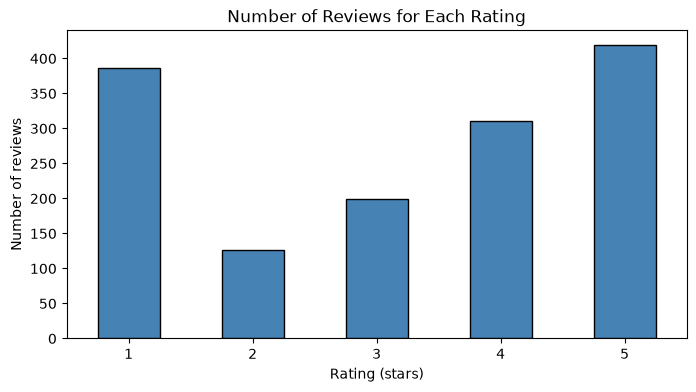

In [23]:
rating_counts = df["rating"].value_counts().sort_index()
print(rating_counts)

rating_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Number of Reviews for Each Rating")
plt.xlabel("Rating (stars)")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

**What this tells us: most reviews are 5-star and 1-star. People usually write a review when they are very happy or very unhappy. 2-star and 3-star reviews are fewer.**

### 3.4 Create the target column (Sentiment)

**Our dataset only has star ratings, but we want to predict sentiment. So we convert the rating into a sentiment label:**

**• 4 and 5 stars → Positive**

**• 3 stars → Neutral**

**• 1 and 2 stars → Negative**

**This new column `sentiment` is our target (the thing the model will learn to predict).**

sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64


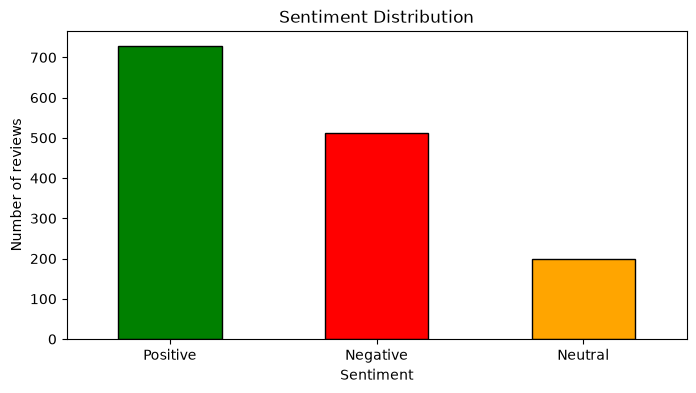

In [26]:
def rating_to_sentiment(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df["sentiment"] = df["rating"].apply(rating_to_sentiment)

sentiment_counts = df["sentiment"].value_counts()
print(sentiment_counts)

sentiment_counts.plot(kind="bar", color=["green", "red", "orange"], edgecolor="black")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

**What this tells us: Positive reviews are the largest group, Negative is second and Neutral is the smallest. This is called class imbalance. The models will find the Neutral class hardest to learn because they see fewer examples of it. We will keep this in mind during evaluation.**

## Step 4: Text Cleaning

**Raw text is messy: it has capital letters, numbers, symbols and extra spaces. Computers treat "Good", "good" and "good!!" as different words. So we clean the text:**

**1. Join the title and the body into one text, because the title also carries opinion (for example "Horrible product").**

**2. Convert everything to lowercase.**

**3. Remove numbers, symbols and punctuation, and keep only letters.**

**4. Remove extra spaces.**

In [30]:
def clean_text(text):
    text = text.lower()                        # lowercase
    text = re.sub(r"[^a-z\s]", " ", text)      # keep only letters and spaces
    text = re.sub(r"\s+", " ", text).strip()   # remove extra spaces
    return text

df["full_text"]  = df["title"] + " " + df["body"]
df["clean_text"] = df["full_text"].apply(clean_text)

# Compare one review before and after cleaning
print("BEFORE:", df["full_text"][3])
print()
print("AFTER :", df["clean_text"][3])

BEFORE: A big no from me 1. It doesn't work with 5.0GHz WiFi frequency. 2.4GHz is very old school.2. Camera quality is pathetic (both front and back). Forget about 48MP, pictures are all blur, poorer than a 4MP one.3. Amazon didn't allow to write a review until they sold most of the stock, something very fishy.4. No return policy, you will have to live with the phone you didn't like. Now you decide.

AFTER : a big no from me it doesn t work with ghz wifi frequency ghz is very old school camera quality is pathetic both front and back forget about mp pictures are all blur poorer than a mp one amazon didn t allow to write a review until they sold most of the stock something very fishy no return policy you will have to live with the phone you didn t like now you decide


## Step 5: Feature Engineering

**Feature engineering means creating new useful columns (features) from existing data. Here we create:**

**• Character count and word count of each review**

**• TextBlob polarity (how positive or negative the text is)**

**• TextBlob subjectivity (how much it is a personal opinion versus a fact)**

### 5.1 Review length features

In [33]:
df["char_count"] = df["clean_text"].apply(len)                    # number of characters
df["word_count"] = df["clean_text"].apply(lambda x: len(x.split()))  # number of words

df[["clean_text", "char_count", "word_count"]].head()

,clean_text,char_count,word_count
0,horrible product very disappointed with the ov...,76,10
1,camera quality is not like megapixel camera qu...,58,10
2,overall got the mobile on the launch date batt...,404,73
3,a big no from me it doesn t work with ghz wifi...,363,74
4,put your money somewhere else not worth buying...,200,36


### 5.2 Sentiment analysis using TextBlob

**TextBlob is a ready-made tool that reads a sentence and gives two scores:**

**• Polarity: from -1 (very negative) to +1 (very positive). 0 means neutral.**

**• Subjectivity: from 0 (pure fact) to 1 (pure personal opinion).**

**TextBlob does not need any training. It uses a built-in dictionary of words and their scores.**

In [36]:
df["polarity"]     = df["clean_text"].apply(lambda t: TextBlob(t).sentiment.polarity)
df["subjectivity"] = df["clean_text"].apply(lambda t: TextBlob(t).sentiment.subjectivity)

# Example on 3 simple sentences
for sentence in ["The camera is excellent", "The battery is terrible", "I bought this phone yesterday"]:
    print(f"{sentence:35s} -> polarity = {TextBlob(sentence).sentiment.polarity:.2f}")

df[["clean_text", "polarity", "subjectivity"]].head()

The camera is excellent             -> polarity = 1.00
The battery is terrible             -> polarity = -1.00
I bought this phone yesterday       -> polarity = 0.00


,clean_text,polarity,subjectivity
0,horrible product very disappointed with the ov...,-0.658333,0.658333
1,camera quality is not like megapixel camera qu...,0.000000,0.300000
2,overall got the mobile on the launch date batt...,0.018182,0.554545
3,a big no from me it doesn t work with ghz wifi...,-0.004805,0.380000
4,put your money somewhere else not worth buying...,0.029762,0.327381


## Step 6: Visualization and Analysis

**Now we use charts to understand the text. Each chart is followed by a short explanation.**

### 6.1 Review length distribution

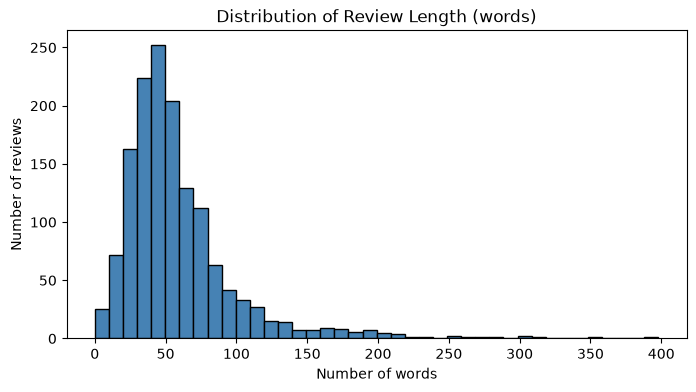

count    1440.0
mean       58.6
std        41.0
min         0.0
25%        34.0
50%        49.0
75%        70.0
max       398.0
Name: word_count, dtype: float64


In [38]:
plt.hist(df["word_count"], bins=40, color="steelblue", edgecolor="black")
plt.title("Distribution of Review Length (words)")
plt.xlabel("Number of words")
plt.ylabel("Number of reviews")
plt.show()

print(df["word_count"].describe().round(1))

**What this tells us: most reviews are short (under about 100 words) and only a few reviews are very long. This is normal for customer reviews.**

### 6.2 Review length for each sentiment

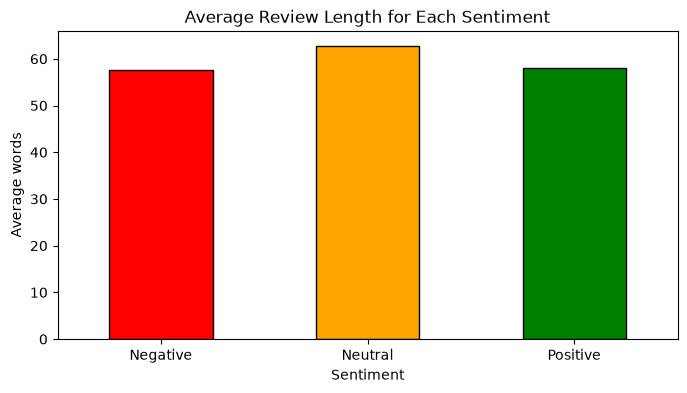

In [40]:
df.groupby("sentiment")["word_count"].mean().round(1).plot(
    kind="bar", color=["red", "orange", "green"], edgecolor="black")
plt.title("Average Review Length for Each Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average words")
plt.xticks(rotation=0)
plt.show()

**What this tells us: this chart shows whether unhappy or happy customers write longer reviews. Review length is a weak clue, so the models will rely mainly on the actual words.**

### 6.3 Most common words (after removing stop words)

**Stop words are very common words like "the", "is", "and" that carry no sentiment. We remove them to see the meaningful words.**

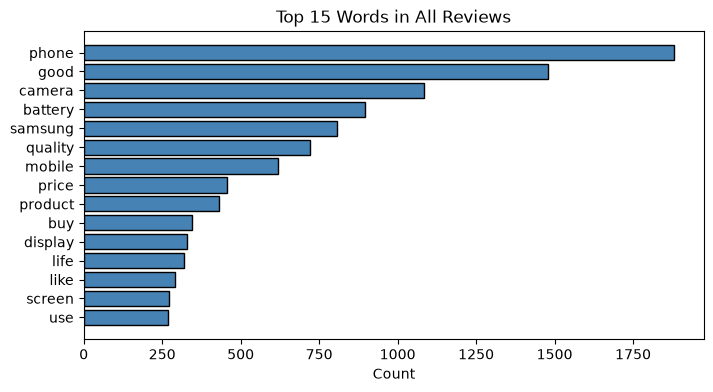

In [44]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def top_words(texts, n=15):
    words = " ".join(texts).split()
    words = [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return Counter(words).most_common(n)

# Top words in all reviews
top_all = top_words(df["clean_text"])
words, counts = zip(*top_all)

plt.barh(words[::-1], counts[::-1], color="steelblue", edgecolor="black")
plt.title("Top 15 Words in All Reviews")
plt.xlabel("Count")
plt.show()

**What this tells us: the most common words are about the product itself (phone, camera, battery, etc.). These words appear in every kind of review, so alone they do not tell us the sentiment.**

### 6.4 Top words in Positive vs Negative reviews

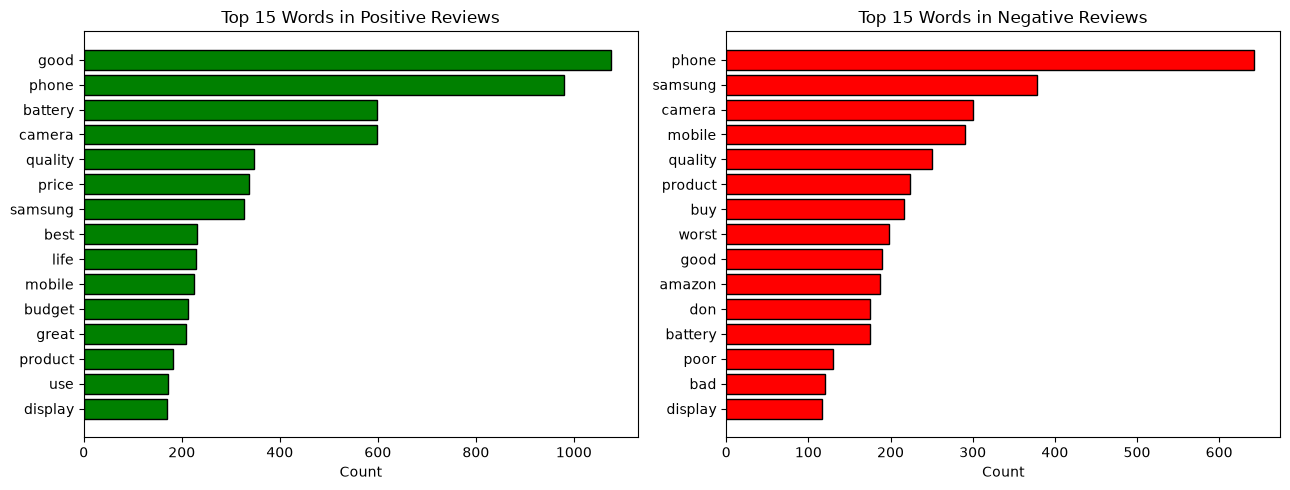

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, sentiment, color in zip(axes, ["Positive", "Negative"], ["green", "red"]):
    top = top_words(df[df["sentiment"] == sentiment]["clean_text"])
    words, counts = zip(*top)
    ax.barh(words[::-1], counts[::-1], color=color, edgecolor="black")
    ax.set_title(f"Top 15 Words in {sentiment} Reviews")
    ax.set_xlabel("Count")

plt.tight_layout()
plt.show()

**What this tells us: Positive reviews use words like good, great and nice, while Negative reviews use words about problems such as not, issue and bad. This difference in vocabulary is exactly what the models will learn.**

### 6.5 TextBlob polarity distribution

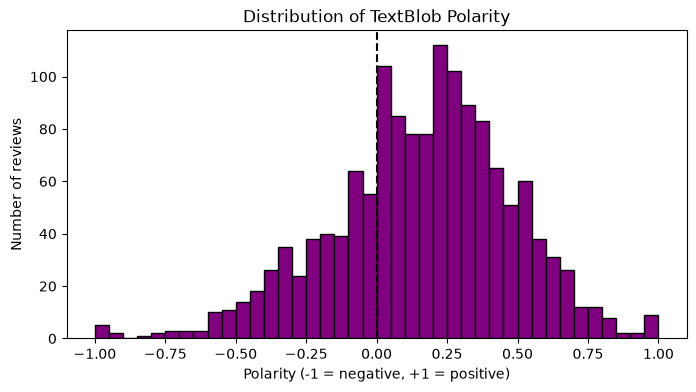

In [50]:
plt.hist(df["polarity"], bins=40, color="purple", edgecolor="black")
plt.axvline(0, color="black", linestyle="--")
plt.title("Distribution of TextBlob Polarity")
plt.xlabel("Polarity (-1 = negative, +1 = positive)")
plt.ylabel("Number of reviews")
plt.show()

**What this tells us: most polarity scores are slightly above zero, so TextBlob sees the reviews as mildly positive overall. This matches the fact that Positive is our biggest class.**

### 6.6 TextBlob polarity for each sentiment

sentiment
Negative   -0.112
Neutral     0.090
Positive    0.370
Name: polarity, dtype: float64


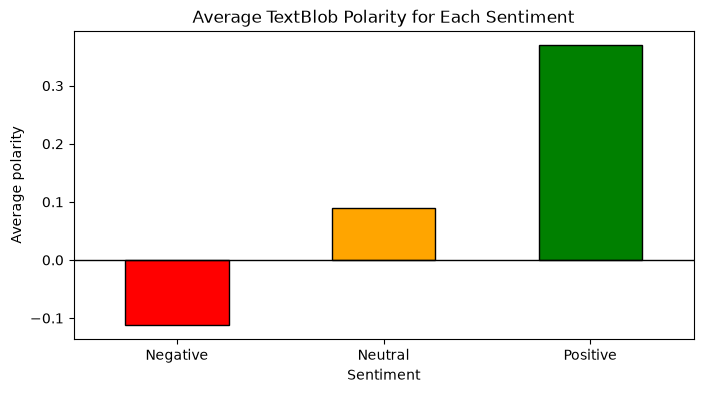

In [54]:
avg_polarity = df.groupby("sentiment")["polarity"].mean().round(3)
print(avg_polarity)

avg_polarity.plot(kind="bar", color=["red", "orange", "green"], edgecolor="black")
plt.axhline(0, color="black", linewidth=1)
plt.title("Average TextBlob Polarity for Each Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average polarity")
plt.xticks(rotation=0)
plt.show()

**What this tells us: average polarity is highest for Positive, in the middle for Neutral and lowest for Negative. This proves that the TextBlob score is a useful feature for our models.**

### 6.7 Polarity box plot

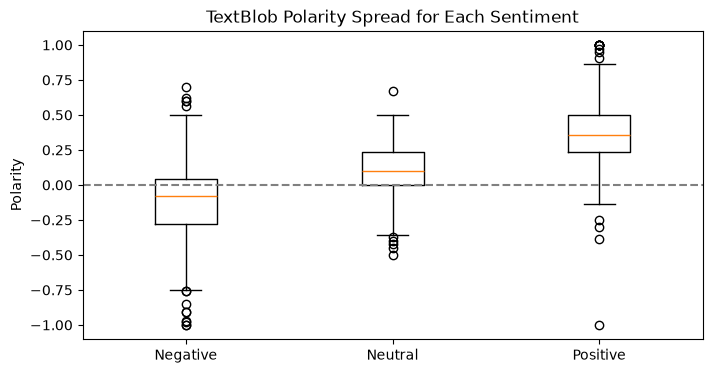

In [57]:
data = [df[df["sentiment"] == s]["polarity"] for s in ["Negative", "Neutral", "Positive"]]
plt.boxplot(data)
plt.xticks([1, 2, 3], ["Negative", "Neutral", "Positive"])
plt.axhline(0, color="gray", linestyle="--")
plt.title("TextBlob Polarity Spread for Each Sentiment")
plt.ylabel("Polarity")
plt.show()

**What this tells us: the box plot shows the spread of scores. The boxes of the three sentiments overlap, especially Neutral with the other two. This is why even a good model will make mistakes on Neutral reviews.**

### 6.8 How well does TextBlob alone match the real labels?

**As a quick experiment, we use TextBlob alone to predict the sentiment (polarity above 0.1 → Positive, below -0.1 → Negative, otherwise Neutral) and compare it with the real sentiment from ratings.**

In [60]:
def polarity_to_sentiment(p):
    if p > 0.1:
        return "Positive"
    elif p < -0.1:
        return "Negative"
    else:
        return "Neutral"

df["textblob_sentiment"] = df["polarity"].apply(polarity_to_sentiment)

textblob_accuracy = accuracy_score(df["sentiment"], df["textblob_sentiment"])
print(f"Accuracy of TextBlob alone: {textblob_accuracy:.2%}")

pd.crosstab(df["sentiment"], df["textblob_sentiment"])

Accuracy of TextBlob alone: 67.64%


textblob_sentiment,Negative,Neutral,Positive
sentiment,,,
Negative,234,183,95
Neutral,31,72,96
Positive,5,56,668


**What this tells us: TextBlob alone gives a decent starting point (this is our baseline), but it is not perfect because it does not learn from our data. Machine learning models trained on our reviews should perform better. Our goal is to beat this baseline accuracy.**

## Step 7: Prepare Data for Modeling

### 7.1 Train-Test Split

**We split the data into two parts:**

**• Training set (80%) → the model learns from these reviews.**

**• Testing set (20%) → we hide these reviews and use them later to check how well the model performs on new data.**

**`stratify` keeps the same Positive / Neutral / Negative ratio in both parts. `random_state=42` makes sure we get the same split every time we run the code.**

In [64]:
X_train_text, X_test_text, y_train, y_test, pol_train, pol_test = train_test_split(
    df["clean_text"],
    df["sentiment"],
    df["polarity"],
    test_size=0.2,
    random_state=42,
    stratify=df["sentiment"]
)

print("Training reviews:", len(X_train_text))
print("Testing reviews :", len(X_test_text))

Training reviews: 1152
Testing reviews : 288


### 7.2 TF-IDF (convert text into numbers)

**Machine learning models only understand numbers, not words. TF-IDF converts each review into a list of numbers.**

**• TF (Term Frequency): how many times a word appears in a review.**

**• IDF (Inverse Document Frequency): how rare the word is across all reviews. Rare words get a higher score.**

**• TF-IDF = TF × IDF. Common words like "phone" get a low score and meaningful words like "pathetic" or "excellent" get a high score.**

**Settings used:**

**• `stop_words="english"` → remove useless words like "the", "is".**

**• `max_features=3000` → keep only the 3,000 most useful words.**

**• `ngram_range=(1, 2)` → use single words and also pairs of words such as "not good".**

**Important: we fit TF-IDF on the training data only and then transform the test data. This way the test data stays completely unseen.**

In [67]:
tfidf = TfidfVectorizer(stop_words="english", max_features=3000, ngram_range=(1, 2))

X_train_tfidf = tfidf.fit_transform(X_train_text)   # learn vocabulary + convert
X_test_tfidf  = tfidf.transform(X_test_text)        # only convert

print("TF-IDF shape of training data:", X_train_tfidf.shape)
print("(rows = reviews, columns = words/word-pairs)")

TF-IDF shape of training data: (1152, 3000)
(rows = reviews, columns = words/word-pairs)


**Let us see which words have the highest average TF-IDF score in the training data.**

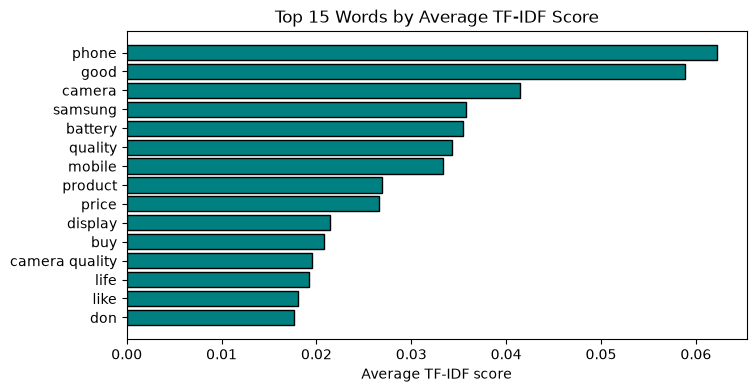

In [70]:
mean_scores = np.asarray(X_train_tfidf.mean(axis=0)).ravel()
feature_names = tfidf.get_feature_names_out()
top_idx = mean_scores.argsort()[::-1][:15]

plt.barh([feature_names[i] for i in top_idx][::-1], mean_scores[top_idx][::-1],
         color="teal", edgecolor="black")
plt.title("Top 15 Words by Average TF-IDF Score")
plt.xlabel("Average TF-IDF score")
plt.show()

### 7.3 Combine TF-IDF with TextBlob polarity

**We add the TextBlob polarity as one extra column next to the TF-IDF columns. Now every review is described by its important words and by its overall sentiment score.**

**Naive Bayes cannot accept negative numbers, but polarity can be negative (-1 to +1). So we shift the polarity into the range 0 to 1 using `(polarity + 1) / 2`.**

In [73]:
pol_train_01 = (pol_train + 1) / 2
pol_test_01  = (pol_test + 1) / 2

X_train = hstack([X_train_tfidf, csr_matrix(pol_train_01.values).T]).tocsr()
X_test  = hstack([X_test_tfidf,  csr_matrix(pol_test_01.values).T]).tocsr()

print("Final training data shape:", X_train.shape)
print("Final testing data shape :", X_test.shape)

Final training data shape: (1152, 3001)
Final testing data shape : (288, 3001)


## Step 8: Model Building and Evaluation (5 Models, One by One)

**We build 5 different classification models. All of them learn the same task: given a review, predict Positive, Neutral or Negative. Each model gets its own section where we train it, test it and evaluate it separately. At the very end (Step 9) we compare all 5 together.**

**Four metrics are used to evaluate every model:**

**• Accuracy: out of all reviews, how many were predicted correctly.**

**• Precision: when the model says "Positive", how often is it really Positive.**

**• Recall: out of all truly Positive reviews, how many did the model find.**

**• F1-Score: a balance between precision and recall. It is the best single number when classes are imbalanced.**

**We use the `weighted` average so that each class is counted according to its size.**

**We also show two things for every model:**

**• Classification report: precision, recall and F1-score for each sentiment separately. `support` is the number of test reviews of that sentiment.**

**• Confusion matrix: a table of right and wrong predictions. Rows are the real sentiments and columns are the predicted sentiments. The diagonal boxes (top-left to bottom-right) are correct predictions and all other boxes are mistakes.**

### Helper function (written once, used for all 5 models)

**To avoid repeating the same code five times, we write one function called `evaluate_model`. We give it the model name and its predictions. It prints the four metrics, the classification report and the confusion matrix, and saves the scores in a list so we can compare all models at the end.**

In [76]:
labels = ["Negative", "Neutral", "Positive"]   # fixed order for reports and charts
results = []          # will store the scores of every model for the final comparison
trained_models = {}   # will store every trained model

def evaluate_model(name, model, y_pred):
    # 1) Calculate the four metrics
    accuracy  = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    recall    = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1        = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    print(f"===== {name} =====")
    print(f"Accuracy  : {accuracy:.3f}")
    print(f"Precision : {precision:.3f}")
    print(f"Recall    : {recall:.3f}")
    print(f"F1-Score  : {f1:.3f}")

    # 2) Classification report (score for each sentiment)
    print()
    print(classification_report(y_test, y_pred, labels=labels, zero_division=0))

    # 3) Confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    # 4) Save the scores and the model for later
    results.append({"Model": name, "Accuracy": accuracy, "Precision": precision,
                    "Recall": recall, "F1-Score": f1})
    trained_models[name] = model

### Model 1: Logistic Regression

**Logistic Regression draws a boundary between the classes using a mathematical formula and gives a probability for each sentiment. It is simple, fast and works very well with text data.**

**`class_weight="balanced"` tells the model to give more importance to the smaller class (Neutral) so that it is not ignored.**

**Steps: create the model → `fit` (learn from training data) → `predict` (guess the sentiment of the unseen test reviews) → evaluate.**

===== Logistic Regression =====
Accuracy  : 0.747
Precision : 0.741
Recall    : 0.747
F1-Score  : 0.744

              precision    recall  f1-score   support

    Negative       0.78      0.80      0.79       102
     Neutral       0.30      0.28      0.29        40
    Positive       0.84      0.84      0.84       146

    accuracy                           0.75       288
   macro avg       0.64      0.64      0.64       288
weighted avg       0.74      0.75      0.74       288



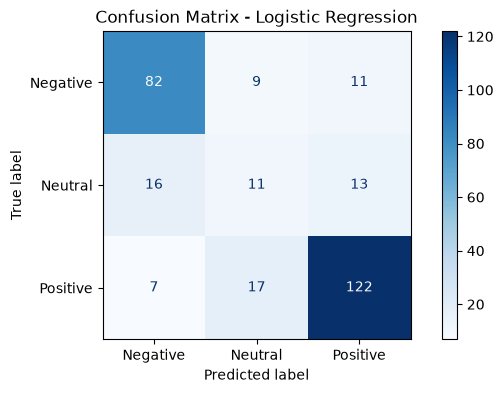

In [79]:
lr_model = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_model.fit(X_train, y_train)          # learn from training data
lr_pred = lr_model.predict(X_test)      # predict on test data

evaluate_model("Logistic Regression", lr_model, lr_pred)

## Model 2: Naive Bayes

**Naive Bayes uses probability. It checks how likely each word is to appear in Positive, Neutral and Negative reviews, and then picks the sentiment with the highest probability. It is very fast and is a classic choice for text classification.**

**This is why we shifted the polarity into the range 0 to 1 earlier, because Naive Bayes cannot accept negative numbers.**

===== Naive Bayes =====
Accuracy  : 0.760
Precision : 0.664
Recall    : 0.760
F1-Score  : 0.702

              precision    recall  f1-score   support

    Negative       0.84      0.75      0.79       102
     Neutral       0.00      0.00      0.00        40
    Positive       0.73      0.98      0.83       146

    accuracy                           0.76       288
   macro avg       0.52      0.57      0.54       288
weighted avg       0.66      0.76      0.70       288



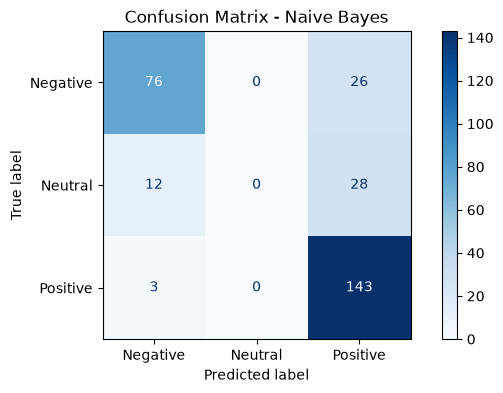

In [82]:
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)

evaluate_model("Naive Bayes", nb_model, nb_pred)

## Model 3: Support Vector Machine (SVM)

**SVM finds the best possible dividing line between the classes, the one with the widest gap between them. We use the linear version (`LinearSVC`) because it is fast and works very well with TF-IDF text data.**

===== SVM (Linear) =====
Accuracy  : 0.753
Precision : 0.728
Recall    : 0.753
F1-Score  : 0.737

              precision    recall  f1-score   support

    Negative       0.75      0.81      0.78       102
     Neutral       0.35      0.20      0.25        40
    Positive       0.82      0.86      0.84       146

    accuracy                           0.75       288
   macro avg       0.64      0.63      0.62       288
weighted avg       0.73      0.75      0.74       288



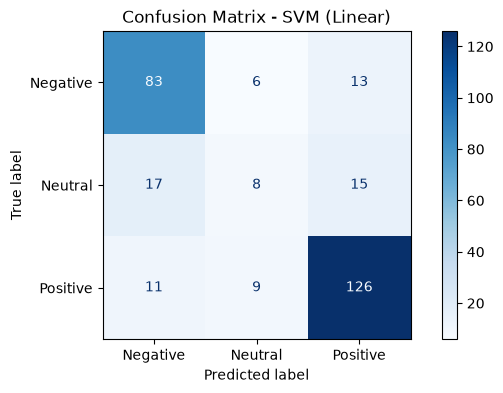

In [85]:
svm_model = LinearSVC(class_weight="balanced")
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

evaluate_model("SVM (Linear)", svm_model, svm_pred)

## Model 4: Decision Tree

**A Decision Tree asks a series of yes/no questions (like a flowchart), for example "does the review contain the word `poor`?", until it reaches a decision.**

**`max_depth=20` limits how many questions the tree can ask. Without a limit, the tree memorizes the training data (this is called overfitting) and performs badly on new reviews.**

===== Decision Tree =====
Accuracy  : 0.743
Precision : 0.725
Recall    : 0.743
F1-Score  : 0.731

              precision    recall  f1-score   support

    Negative       0.74      0.82      0.78       102
     Neutral       0.38      0.25      0.30        40
    Positive       0.81      0.82      0.81       146

    accuracy                           0.74       288
   macro avg       0.64      0.63      0.63       288
weighted avg       0.72      0.74      0.73       288



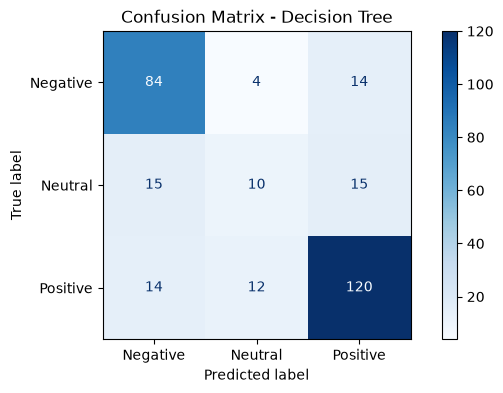

In [88]:
dt_model = DecisionTreeClassifier(max_depth=20, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

evaluate_model("Decision Tree", dt_model, dt_pred)

## Model 5: Random Forest

**Random Forest builds many decision trees (here 200) and lets them vote. The sentiment with the most votes is the final answer. Because many trees vote together, it is usually more stable and accurate than a single Decision Tree.**

===== Random Forest =====
Accuracy  : 0.778
Precision : 0.741
Recall    : 0.778
F1-Score  : 0.726

              precision    recall  f1-score   support

    Negative       0.76      0.85      0.80       102
     Neutral       0.50      0.03      0.05        40
    Positive       0.80      0.93      0.86       146

    accuracy                           0.78       288
   macro avg       0.68      0.60      0.57       288
weighted avg       0.74      0.78      0.73       288



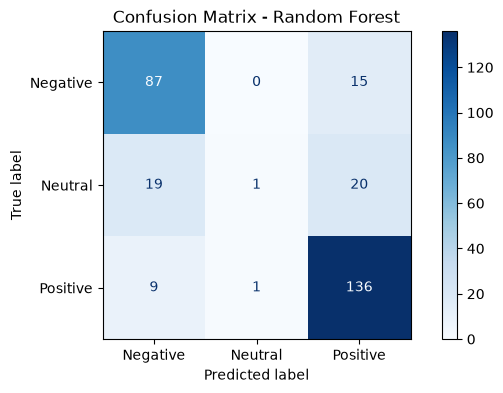

In [91]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

evaluate_model("Random Forest", rf_model, rf_pred)

## Step 9: Final Evaluation of All 5 Models

**Now that every model is trained and evaluated separately, we put all the scores together in one table and one chart to find the best model.**

### 9.1 Comparison table

**The table is sorted from best to worst by F1-Score.**

In [93]:
results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False).round(3).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.747,0.741,0.747,0.744
1,SVM (Linear),0.753,0.728,0.753,0.737
2,Decision Tree,0.743,0.725,0.743,0.731
3,Random Forest,0.778,0.741,0.778,0.726
4,Naive Bayes,0.760,0.664,0.760,0.702


### 9.2 Comparison chart

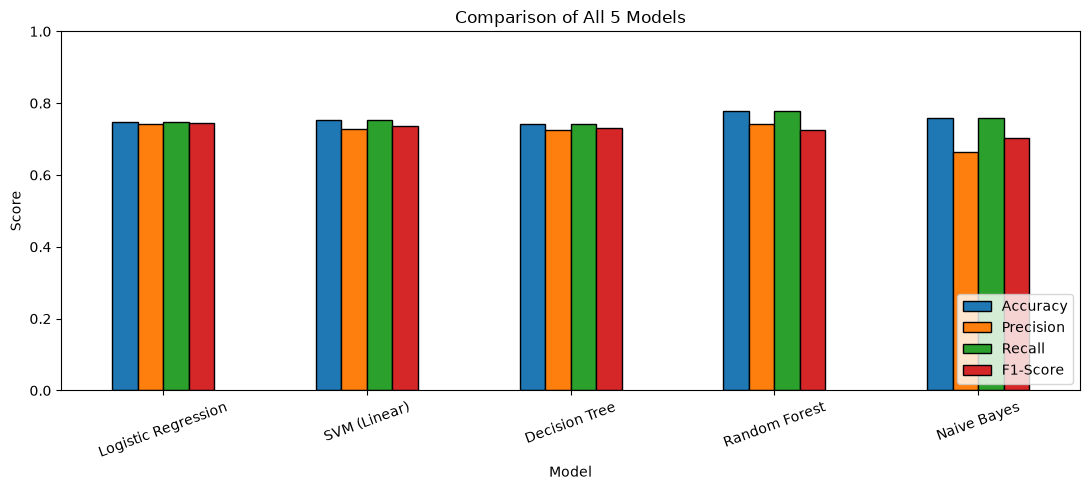

In [95]:
results_df.plot(x="Model", y=["Accuracy", "Precision", "Recall", "F1-Score"],
                kind="bar", figsize=(11, 5), edgecolor="black")
plt.title("Comparison of All 5 Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**What this tells us: the model at the top of the table and with the tallest bars is the best one. Compare every model with the TextBlob baseline accuracy from Step 6.8 to see how much the machine learning models improved on it.**

### 9.3 Best model

In [97]:
best_name = results_df.loc[0, "Model"]
best_model = trained_models[best_name]

print("Best model (highest F1-Score):", best_name)
print("Accuracy :", results_df.loc[0, "Accuracy"])
print("F1-Score :", results_df.loc[0, "F1-Score"])

Best model (highest F1-Score): Logistic Regression
Accuracy : 0.747
F1-Score : 0.744


### 9.4 Test the best model on new reviews

**Finally, we create a small function. It takes any new review, applies the same cleaning, TF-IDF and TextBlob steps and returns the predicted sentiment. This same function will be used later during deployment.**

In [103]:
def predict_sentiment(review):
    cleaned = clean_text(review)                               # same cleaning
    tfidf_numbers = tfidf.transform([cleaned])                 # same TF-IDF
    polarity = (TextBlob(cleaned).sentiment.polarity + 1) / 2  # same TextBlob feature
    final_input = hstack([tfidf_numbers, csr_matrix([[polarity]])]).tocsr()
    return best_model.predict(final_input)[0]

new_reviews = [
    "Amazing phone, battery lasts all day and camera is superb",
    "Worst phone ever, screen stopped working in a week",
    "It is okay, nothing special for the price",
]

for review in new_reviews:
    print(f"{predict_sentiment(review):9s} <- {review}")

Positive  <- Amazing phone, battery lasts all day and camera is superb
Negative  <- Worst phone ever, screen stopped working in a week
Positive  <- It is okay, nothing special for the price


## Step 10: Conclusion

**1. We explored the data: 1,440 reviews, no missing values, no duplicates, and more Positive reviews than Negative or Neutral.**

**2. We cleaned the text and created features: review length, TextBlob polarity and subjectivity.**

**3. We converted text into numbers using TF-IDF and combined it with the TextBlob polarity score.**

**4. We built 5 models (Logistic Regression, Naive Bayes, SVM, Decision Tree and Random Forest) and compared them using accuracy, precision, recall and F1-score.**

**5. The best model is chosen using the F1-score from the comparison table. All models are weakest on the Neutral class because of fewer examples and mixed opinions.**

**Possible improvements: collect more Neutral reviews, try hyperparameter tuning, or use deep learning models such as BERT.**

**Next milestone: Deployment of the best model using Streamlit.**

## Step 11: Deployment with Streamlit

**Best model for deployment: Logistic Regression.**

**Why we chose it:**

**• It has the highest weighted F1-score (0.744) of all 5 models.**

**• It is the only model that handles all three classes reasonably. Random Forest and Naive Bayes have higher accuracy, but they almost never predict Neutral (recall 0.03 and 0.00).**

**• It gives probabilities (for example 82% Positive), so the app can show how confident the model is. Linear SVM cannot do this.**

**• It is simple, fast and small, which suits Streamlit Cloud.**

**Streamlit turns a Python file into a web app. We need 3 files in one folder:**

**1. `app.py` → the web app code (next cell)**

**2. `requirements.txt` → the libraries the app needs (cell after that)**

**3. `P719-Dataset.xlsx` → your dataset (rename your file to exactly this name). The app trains the model once when it starts, using the same steps as this notebook.**

### 11.1 The app code (`app.py`)

**Running the cell below saves the file `app.py` in the same folder as this notebook.**

In [ ]:
%%writefile app.py
# ============================================================
#  Amazon Phone Review Sentiment Analyzer  (P719)
#  Model: Logistic Regression + TF-IDF + TextBlob polarity
#  Live app: https://sentiment-analysis-dkoa46fknf4fcmnk7gzzan.streamlit.app/
# ============================================================
import re
import pandas as pd
import streamlit as st
from textblob import TextBlob
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

st.set_page_config(page_title="Review Sentiment Analyzer", page_icon="📱")

# ---------- 1. Helper functions (same steps as the notebook) ----------
def clean_text(text):
    text = str(text).lower()                      # lowercase
    text = re.sub(r"[^a-z\s]", " ", text)         # keep only letters
    return re.sub(r"\s+", " ", text).strip()      # remove extra spaces

def polarity_feature(cleaned_text):
    return (TextBlob(cleaned_text).sentiment.polarity + 1) / 2   # scale -1..1 to 0..1

def rating_to_sentiment(rating):
    if rating >= 4:
        return "Positive"
    if rating == 3:
        return "Neutral"
    return "Negative"

# ---------- 2. Train the model once (cached, so the app stays fast) ----------
@st.cache_resource
def train_model():
    df = pd.read_excel("P719-Dataset.xlsx")
    df["sentiment"] = df["rating"].apply(rating_to_sentiment)
    df["clean_text"] = (df["title"].fillna("").astype(str) + " " + df["body"].fillna("").astype(str)).apply(clean_text)
    df["polarity"] = df["clean_text"].apply(polarity_feature)

    X_train_text, X_test_text, y_train, y_test, pol_train, pol_test = train_test_split(
        df["clean_text"], df["sentiment"], df["polarity"],
        test_size=0.2, random_state=42, stratify=df["sentiment"])

    tfidf = TfidfVectorizer(stop_words="english", max_features=3000, ngram_range=(1, 2))
    X_train = hstack([tfidf.fit_transform(X_train_text), csr_matrix(pol_train.values).T]).tocsr()
    X_test = hstack([tfidf.transform(X_test_text), csr_matrix(pol_test.values).T]).tocsr()

    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    scores = {
        "accuracy": accuracy_score(y_test, predictions),
        "f1": f1_score(y_test, predictions, average="weighted"),
        "reviews": len(df),
    }
    return model, tfidf, scores

model, tfidf, scores = train_model()

def predict(reviews):
    """Takes a list of reviews, returns predicted labels and probabilities."""
    cleaned = [clean_text(r) for r in reviews]
    polarity = csr_matrix([[polarity_feature(c)] for c in cleaned])
    features = hstack([tfidf.transform(cleaned), polarity]).tocsr()
    return model.predict(features), model.predict_proba(features)

# ---------- 3. Page layout ----------
st.title("📱 Phone Review Sentiment Analyzer")
st.caption("Paste a customer review and find out if it is Positive, Neutral or Negative.")

with st.sidebar:
    st.header("About the model")
    st.write("**Logistic Regression** trained on Amazon phone reviews using TF-IDF and TextBlob polarity.")
    st.metric("Test accuracy", f"{scores['accuracy']:.1%}")
    st.metric("Weighted F1-score", f"{scores['f1']:.1%}")
    st.metric("Reviews used", scores["reviews"])
    st.info("Neutral reviews are the hardest to predict, because they often mix good and bad opinions.")

COLORS = {"Positive": "#16a34a", "Neutral": "#f59e0b", "Negative": "#dc2626"}
EMOJIS = {"Positive": "😊", "Neutral": "😐", "Negative": "😠"}

tab_single, tab_batch = st.tabs(["✍️ Single review", "📂 Many reviews (file)"])

# ---------- Tab 1: one review ----------
with tab_single:
    st.write("Try an example:")
    examples = {
        "😊 Positive": "Amazing phone, battery lasts all day and the camera is superb!",
        "😠 Negative": "Worst phone ever, the screen stopped working in a week.",
        "😐 Mixed": "Camera is good but the battery drains very fast. Average phone overall.",
    }
    columns = st.columns(3)
    for column, (label, text) in zip(columns, examples.items()):
        if column.button(label, use_container_width=True):
            st.session_state["review"] = text

    review = st.text_area("Your review", key="review", height=150,
                          placeholder="Type or paste a phone review here...")

    if st.button("Analyze sentiment", type="primary"):
        if not review.strip():
            st.warning("Please enter a review first.")
        else:
            labels, probabilities = predict([review])
            result = labels[0]
            chances = dict(zip(model.classes_, probabilities[0]))

            st.markdown(
                f"""<div style="padding:20px; border-radius:12px; text-align:center;
                     background-color:{COLORS[result]}22; border:2px solid {COLORS[result]};">
                     <div style="font-size:42px;">{EMOJIS[result]}</div>
                     <div style="font-size:26px; font-weight:700; color:{COLORS[result]};">{result}</div>
                     <div>Confidence: {chances[result]:.0%}</div></div>""",
                unsafe_allow_html=True)

            st.write("")
            st.subheader("How sure is the model?")
            for name in ["Positive", "Neutral", "Negative"]:
                st.write(f"{EMOJIS[name]} {name}: **{chances[name]:.0%}**")
                st.progress(float(chances[name]))

            if chances[result] < 0.5:
                st.info("The model is not very confident about this review.")

# ---------- Tab 2: a file with many reviews ----------
with tab_batch:
    st.write("Upload a CSV or Excel file that has a column of reviews.")
    file = st.file_uploader("Choose a file", type=["csv", "xlsx"])

    if file is not None:
        data = pd.read_csv(file) if file.name.endswith(".csv") else pd.read_excel(file)
        review_column = st.selectbox("Which column contains the reviews?", data.columns)

        if st.button("Analyze all reviews", type="primary"):
            labels, _ = predict(data[review_column].fillna("").astype(str).tolist())
            data["predicted_sentiment"] = labels

            st.subheader("Summary")
            st.bar_chart(data["predicted_sentiment"].value_counts())
            st.dataframe(data, use_container_width=True)
            st.download_button("⬇️ Download results", data.to_csv(index=False),
                               file_name="sentiment_results.csv", mime="text/csv")


### 11.2 The libraries file (`requirements.txt`)

**Streamlit Cloud reads this file and installs these libraries automatically.**

In [ ]:
%%writefile requirements.txt
streamlit
pandas
numpy
scipy
scikit-learn
textblob
openpyxl


### 11.3 Test the app on your own computer

**Open Anaconda Prompt (or a terminal), go to the folder that has the 3 files and run:**

**`pip install -r requirements.txt`**

**`streamlit run app.py`**

**The app opens in your browser. Test it before deploying.**

### 11.4 Make it always live on Streamlit Cloud

**1. Create a new public GitHub repository, for example `sentiment-analyzer`.**

**2. Upload `app.py`, `requirements.txt` and `P719-Dataset.xlsx` to it.**

**3. Go to share.streamlit.io and sign in with GitHub.**

**4. Click Create app, choose your repository, set the main file to `app.py` and click Deploy.**

**5. After a minute or two you get a public link that you can share on LinkedIn.**

**Note: on the free tier, the app goes to sleep after a few days without visitors. Opening the link wakes it up again.**

### 11.5 Live App

**The app is deployed and always live on Streamlit Cloud. Anyone can open it, type a phone review and see the predicted sentiment:**

**👉 [https://sentiment-analysis-dkoa46fknf4fcmnk7gzzan.streamlit.app/](https://sentiment-analysis-dkoa46fknf4fcmnk7gzzan.streamlit.app/)**